# Experiment 2: Data Preprocessing for Generative AI Applications

**Aim:** Prepare tabular, image, text and audio data for generative models: cleaning, imputation, scaling,
encoding, normalisation, augmentation, tokenisation, padding and efficient `tf.data` input pipelines.

In [1]:
import os, re, collections
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)
print("TensorFlow", tf.__version__)

I0000 00:00:1792688858.134744    2670 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792688860.500370    2670 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0


## Part A - Tabular data: missing values, outliers, scaling and encoding
We create a deliberately messy customer table (missing values, an outlier, categorical columns, duplicate rows).

In [2]:
n = 500
df = pd.DataFrame({
    "age": rng.normal(38, 11, n).round(),
    "income": rng.lognormal(10.5, 0.5, n).round(),
    "city": rng.choice(["Mumbai", "Pune", "Delhi", "Chennai"], n),
    "plan": rng.choice(["basic", "pro", "premium"], n, p=[0.5, 0.3, 0.2]),
    "score": rng.normal(600, 80, n).round(),
})
df.loc[rng.choice(n, 40, replace=False), "age"] = np.nan
df.loc[rng.choice(n, 30, replace=False), "income"] = np.nan
df.loc[rng.choice(n, 25, replace=False), "city"] = np.nan
df.loc[7, "income"] = 9_000_000                      # extreme outlier
df = pd.concat([df, df.iloc[:10]], ignore_index=True)  # duplicate rows
print(df.head(), "\n")
print("shape:", df.shape, "| duplicates:", df.duplicated().sum())
print("\nMissing values per column:\n", df.isna().sum())
print("\nSummary statistics:\n", df.describe().round(1))

    age   income     city   plan  score
0  39.0  69317.0  Chennai  basic  618.0
1  37.0  45562.0  Chennai    pro  658.0
2  45.0  15598.0  Chennai    pro  654.0
3  39.0  25233.0     Pune  basic  592.0
4  32.0  67249.0     Pune    pro  612.0 

shape: (510, 5) | duplicates: 10

Missing values per column:
 age       41
income    30
city      26
plan       0
score      0
dtype: int64

Summary statistics:
          age     income  score
count  469.0      480.0  510.0
mean    37.7    76659.3  595.9
std     11.1   578134.6   81.1
min     -3.0     8400.0  399.0
25%     30.0    25758.2  538.2
50%     37.0    35171.5  593.0
75%     45.0    47644.0  653.0
max     72.0  9000000.0  815.0


income IQR fence: [-6,914, 80,247]  -> 21 values above fence
rows after de-duplication: 500


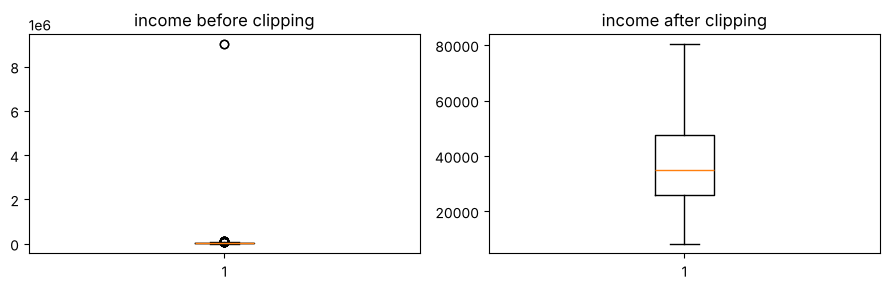

In [3]:
clean = df.drop_duplicates().reset_index(drop=True)
q1, q3 = clean["income"].quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"income IQR fence: [{lo:,.0f}, {hi:,.0f}]  -> {(clean.income > hi).sum()} values above fence")
clean["income"] = clean["income"].clip(upper=hi)
print("rows after de-duplication:", len(clean))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].boxplot(df["income"].dropna()); ax[0].set_title("income before clipping")
ax[1].boxplot(clean["income"].dropna()); ax[1].set_title("income after clipping")
plt.tight_layout(); plt.show()

In [4]:
num_cols, cat_cols = ["age", "income", "score"], ["city", "plan"]
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
train, test = train_test_split(clean, test_size=0.2, random_state=0)   # split BEFORE fitting to avoid leakage
Xtr = pre.fit_transform(train); Xte = pre.transform(test)
names = pre.get_feature_names_out()
print("train matrix:", Xtr.shape, "| test matrix:", Xte.shape)
print("features:", list(names))
print("NaNs left :", int(np.isnan(np.asarray(Xtr.todense() if hasattr(Xtr, 'todense') else Xtr)).sum()))
tr = pd.DataFrame(Xtr.toarray() if hasattr(Xtr, "toarray") else Xtr, columns=names)
print("\nScaled numeric columns (train): mean ~ 0, std ~ 1")
print(tr[[c for c in names if c.startswith("num")]].agg(["mean", "std"]).round(3))

train matrix: (400, 10) | test matrix: (100, 10)
features: ['num__age', 'num__income', 'num__score', 'cat__city_Chennai', 'cat__city_Delhi', 'cat__city_Mumbai', 'cat__city_Pune', 'cat__plan_basic', 'cat__plan_premium', 'cat__plan_pro']
NaNs left : 0

Scaled numeric columns (train): mean ~ 0, std ~ 1
      num__age  num__income  num__score
mean     0.000       -0.000      -0.000
std      1.001        1.001       1.001


## Part B - Image data: normalisation, resizing, augmentation, tf.data

raw  : (60000, 28, 28) uint8 0 255


scaled to [-1,1]: -1.0 1.0 | mean -0.428 std 0.706


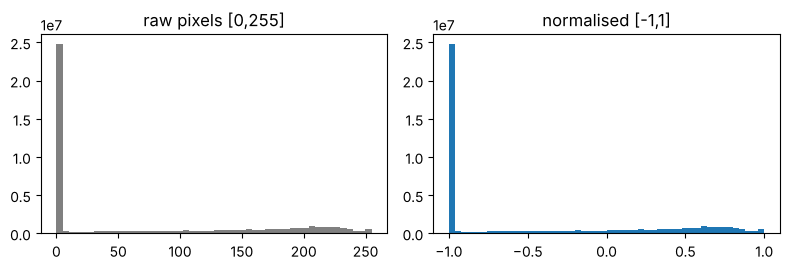

In [5]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
classes = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]
print("raw  :", x_train.shape, x_train.dtype, x_train.min(), x_train.max())
x = (x_train.astype("float32") - 127.5) / 127.5      # GAN-friendly range matching a tanh generator output
print("scaled to [-1,1]:", x.min(), x.max(), "| mean %.3f std %.3f" % (x.mean(), x.std()))
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].hist(x_train.ravel(), bins=50, color="gray"); ax[0].set_title("raw pixels [0,255]")
ax[1].hist(x.ravel(), bins=50, color="tab:blue"); ax[1].set_title("normalised [-1,1]")
plt.tight_layout(); plt.show()

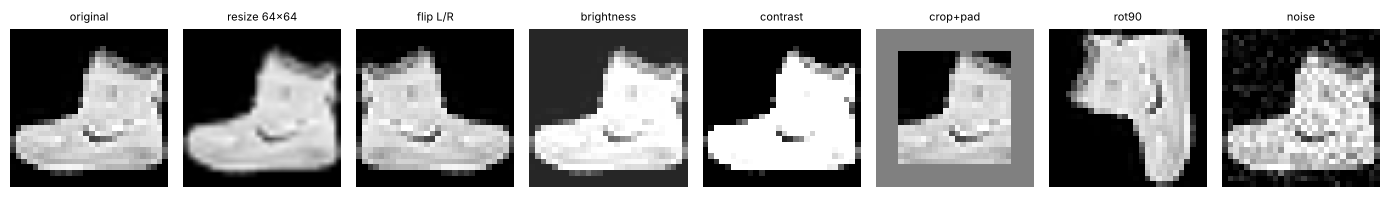

shapes: {'original': (28, 28, 1), 'resize 64x64': (64, 64, 1), 'flip L/R': (28, 28, 1), 'brightness': (28, 28, 1), 'contrast': (28, 28, 1), 'crop+pad': (28, 28, 1), 'rot90': (28, 28, 1), 'noise': (28, 28, 1)}


In [6]:
img = tf.convert_to_tensor(x[0][..., None])
aug = {
    "original": img,
    "resize 64x64": tf.image.resize(img, (64, 64)),
    "flip L/R": tf.image.flip_left_right(img),
    "brightness": tf.image.adjust_brightness(img, 0.3),
    "contrast": tf.image.adjust_contrast(img, 2.0),
    "crop+pad": tf.image.resize_with_crop_or_pad(tf.image.central_crop(img, 0.7), 28, 28),
    "rot90": tf.image.rot90(img),
    "noise": img + 0.2 * tf.random.normal(img.shape),
}
fig, axes = plt.subplots(1, len(aug), figsize=(14, 2.2))
for a, (k, v) in zip(axes, aug.items()):
    a.imshow(np.clip(v.numpy()[..., 0], -1, 1), cmap="gray", vmin=-1, vmax=1); a.set_title(k, fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()
print("shapes:", {k: tuple(v.shape) for k, v in aug.items()})

batch images: (128, 28, 28, 1) <dtype: 'float32'> | labels: (128,)
batch range : [-1.00, 1.00]
batches/epoch: 469


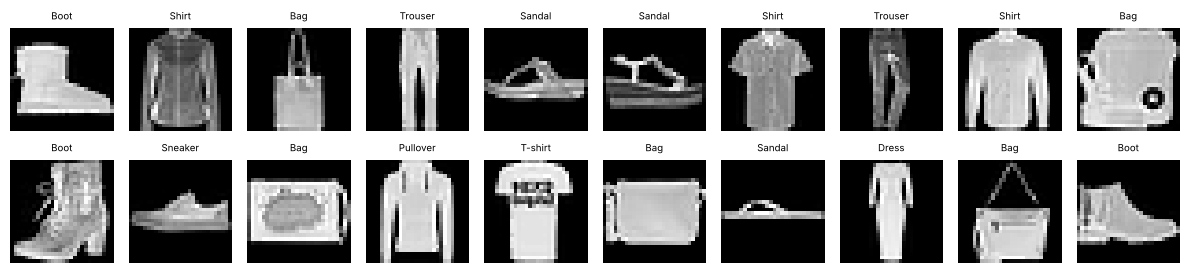

In [7]:
def preprocess(image, label):
    image = tf.cast(image, tf.float32)[..., None]
    image = (image - 127.5) / 127.5
    image = tf.image.random_flip_left_right(image)
    return image, label

ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
      .shuffle(10_000, seed=0).map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
      .batch(128).prefetch(tf.data.AUTOTUNE))
bx, by = next(iter(ds))
print("batch images:", bx.shape, bx.dtype, "| labels:", by.shape)
print("batch range : [%.2f, %.2f]" % (bx.numpy().min(), bx.numpy().max()))
print("batches/epoch:", len(ds))
fig, axes = plt.subplots(2, 10, figsize=(12, 2.9))
for a, im, lb in zip(axes.ravel(), bx.numpy(), by.numpy()):
    a.imshow(im[..., 0], cmap="gray"); a.set_title(classes[lb], fontsize=7); a.axis("off")
plt.tight_layout(); plt.show()

## Part C - Text data: cleaning, tokenisation, vocabulary and padding

In [8]:
path = keras.utils.get_file("shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read()
print("characters:", len(text), "| unique characters:", len(set(text)))
print("--- first 250 characters ---\n" + text[:250])
lines = [l.strip() for l in text.split("\n") if l.strip() and not l.strip().endswith(":")]
def clean_line(s):
    s = s.lower()
    s = re.sub(r"[^a-z' ,.!?;]", " ", s)
    return re.sub(r"\s+", " ", s).strip()
cl = [clean_line(l) for l in lines]
print("\nraw  :", lines[3]); print("clean:", cl[3])
print("non-empty lines:", len(cl))

characters: 1115394 | unique characters: 65
--- first 250 characters ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.


raw  : Resolved. resolved.
clean: resolved. resolved.
non-empty lines: 24015


vocabulary size: 3000 | first 15 tokens: ['', '[UNK]', 'the', 'and', 'to', 'i', 'of', 'my', 'a', 'you', 'that', 'in', 'is', 'for', 'with']

 text: resolved. resolved.
 ids : [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
 back: [UNK] [UNK]

 text: first, you know caius marcius is chief enemy to the people.
 ids : [488, 9, 85, 1186, 582, 12, 1, 996, 4, 2, 1445, 0]
 back: first, you know caius marcius is [UNK] enemy to the people.

 text: we know't, we know't.
 ids : [32, 1, 32, 1, 0, 0, 0, 0, 0, 0, 0, 0]
 back: we [UNK] we [UNK]


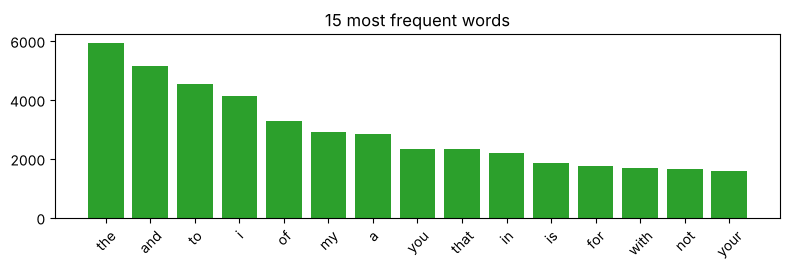

In [9]:
vec = keras.layers.TextVectorization(max_tokens=3000, output_mode="int", output_sequence_length=12, standardize=None, split="whitespace")
vec.adapt(cl)
vocab = [str(w) for w in vec.get_vocabulary()]
print("vocabulary size:", len(vocab), "| first 15 tokens:", vocab[:15])
sample = cl[3:6]
ids = vec(sample).numpy()
for s, i in zip(sample, ids):
    print(f"\n text: {s}\n ids : {i.tolist()}\n back: {' '.join(vocab[t] for t in i if t != 0)}")
cnt = collections.Counter(w for l in cl for w in l.split())
top = cnt.most_common(15)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar([w for w, _ in top], [c for _, c in top], color="tab:green"); ax.set_title("15 most frequent words")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [10]:
vocab_c = sorted(set(text))
c2i = {c: i for i, c in enumerate(vocab_c)}
enc = np.array([c2i[c] for c in text], dtype=np.int32)
seq = 100
windows = tf.data.Dataset.from_tensor_slices(enc).batch(seq + 1, drop_remainder=True)
pairs = windows.map(lambda w: (w[:-1], w[1:]))
xb, yb = next(iter(pairs.batch(2)))
print("char vocabulary size:", len(vocab_c))
print("number of (input, target) windows:", len(enc) // (seq + 1))
print("input  :", repr("".join(vocab_c[i] for i in xb[0][:40].numpy())))
print("target :", repr("".join(vocab_c[i] for i in yb[0][:40].numpy())), "(shifted by one character)")

char vocabulary size: 65
number of (input, target) windows: 11043
input  : 'First Citizen:\nBefore we proceed any fur'
target : 'irst Citizen:\nBefore we proceed any furt' (shifted by one character)


## Part D - Audio data: waveform normalisation and spectrograms

waveform: (16000,) | STFT: (122, 257) | log-mel spectrogram: (122, 64)


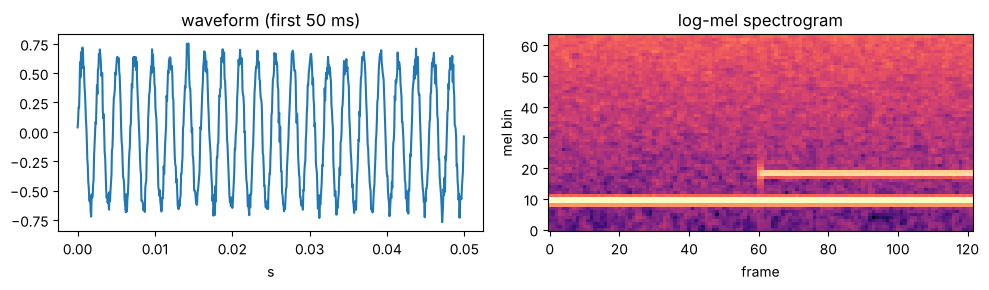

In [11]:
sr = 16000
t = np.arange(0, 1.0, 1 / sr)
sig = (0.6 * np.sin(2 * np.pi * 440 * t) + 0.3 * np.sin(2 * np.pi * 880 * t) * (t > 0.5)
       + 0.05 * rng.standard_normal(len(t))).astype("float32")
sig = sig / np.max(np.abs(sig))                       # peak-normalise to [-1, 1]
stft = tf.signal.stft(sig, frame_length=512, frame_step=128, fft_length=512)
mag = tf.abs(stft)
mel_w = tf.signal.linear_to_mel_weight_matrix(64, 257, sr, 80, 7600)
mel = tf.math.log(tf.tensordot(mag, mel_w, 1) + 1e-6)
print("waveform:", sig.shape, "| STFT:", stft.shape, "| log-mel spectrogram:", mel.shape)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(t[:800], sig[:800]); ax[0].set_title("waveform (first 50 ms)"); ax[0].set_xlabel("s")
ax[1].imshow(mel.numpy().T, origin="lower", aspect="auto", cmap="magma"); ax[1].set_title("log-mel spectrogram")
ax[1].set_xlabel("frame"); ax[1].set_ylabel("mel bin")
plt.tight_layout(); plt.show()